In [ ]:
!pip install kaggle
import os
# kaggle.json ফাইল আপলোড করার জন্য
from google.colab import files
files.upload()

# ফোল্ডার পারমিশন সেট করা
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# সরাসরি ডেটাসেট ডাউনলোড ও আনজিপ করা
!kaggle datasets download -d ronakp004/autism-spectrum-detection-from-kaggle-zenodo
!unzip -q autism-spectrum-detection-from-kaggle-zenodo.zip -d "ASD Data"

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/ronakp004/autism-spectrum-detection-from-kaggle-zenodo
License(s): MIT
100% 4.93G/4.93G [00:53<00:00, 99.1MB/s]



In [ ]:
import os
import pandas as pd

root_dir = "ASD Data"
print("=== CSV Files Row Count Analysis ===")
for root, dirs, files in os.walk(root_dir):
    for file in files:
        if file.endswith('.csv'):
            file_path = os.path.join(root, file)
            try:
                df = pd.read_csv(file_path)
                print(f"{file_path} ---> Total Rows: {len(df)}")
            except Exception as e:
                print(f"Could not read {file_path}: {e}")

=== CSV Files Row Count Analysis ===
ASD Data/ASD Facial Image Dataset Combined/train.csv ---> Total Rows: 8609
ASD Data/ASD Facial Image Dataset Combined/valid.csv ---> Total Rows: 1785
ASD Data/ASD Facial Image Dataset Combined/test.csv ---> Total Rows: 1985
ASD Data/Facial dataset of autistic children/train.csv ---> Total Rows: 1737
ASD Data/Facial dataset of autistic children/test.csv ---> Total Rows: 580
ASD Data/Facial dataset of autistic children/val.csv ---> Total Rows: 580
ASD Data/Cleaned Dataset/cleaned_train.csv ---> Total Rows: 8496
ASD Data/Cleaned Dataset/cleaned_test.csv ---> Total Rows: 1966
ASD Data/Cleaned Dataset/cleaned_valid.csv ---> Total Rows: 1782


In [ ]:
import os
import shutil

# মূল রুট ফোল্ডার
source_dir = "ASD Data"

# আপনার কাঙ্ক্ষিত নতুন ৩টি মূল ফোল্ডার
base_output = "ASD Data/Perfect_Organized_Dataset"
splits = ['train1', 'test1', 'valid1']

# প্রতিটি মেইন ফোল্ডারের ভেতরে দুটি করে সাব-ফোল্ডার (ক্লাস) তৈরি করা
for split in splits:
    os.makedirs(os.path.join(base_output, split, "autistic"), exist_ok=True)
    os.makedirs(os.path.join(base_output, split, "non_autistic"), exist_ok=True)

counters = {"train1": 0, "test1": 0, "valid1": 0}

for root, dirs, files in os.walk(source_dir):
    # আমাদের তৈরি করা আউটপুট ফোল্ডারে যেন আবার সার্চ না করে
    if "Perfect_Organized_Dataset" in root:
        continue

    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            src_path = os.path.join(root, file)
            lower_root = root.lower()

            # ১. ফোল্ডারের পাথ চেক করে নির্ধারণ করা এটি train, test নাকি valid ফোল্ডারের ছবি
            if '/train/' in lower_root or root.endswith('/train') or '\\train\\' in lower_root or root.endswith('\\train'):
                split_folder = "train1"
            elif '/test/' in lower_root or root.endswith('/test') or '\\test\\' in lower_root or root.endswith('\\test'):
                split_folder = "test1"
            elif '/valid/' in lower_root or root.endswith('/valid') or '\\valid\\' in lower_root or root.endswith('\\valid') or '/val/' in lower_root or root.endswith('\\val'):
                split_folder = "valid1"
            else:
                continue # যদি ফোল্ডারটি train/test/valid এর কোনোটি না হয়

            # ২. ক্লাস নির্ধারণ করা (autistic নাকি non_autistic/tipical)
            if 'non' in lower_root or 'normal' in lower_root or 'tipical' in lower_root or 'typical' in lower_root:
                class_name = "non_autistic"
            elif 'autistic' in lower_root or 'autism' in lower_root:
                class_name = "autistic"
            else:
                continue

            # ৩. ফাইলের নাম যেন ডুপ্লিকেট হয়ে ওভাররাইট না হয়, তাই আগের ফোল্ডারের নাম যোগ করা হলো
            parent_folder_name = os.path.basename(os.path.dirname(root))
            current_folder_name = os.path.basename(root)
            new_file_name = f"{parent_folder_name}_{current_folder_name}_{file}"

            dst_path = os.path.join(base_output, split_folder, class_name, new_file_name)

            try:
                shutil.copy(src_path, dst_path)
                counters[split_folder] += 1
            except Exception as e:
                pass

print(f"\n==========================================")
print(f"Dataset Successfully Re-Organized by Categories!")
print(f"-> train1 Folder Total Images: {counters['train1']}")
print(f"-> test1 Folder Total Images: {counters['test1']}")
print(f"-> valid1 Folder Total Images: {counters['valid1']}")
print(f"Saved Location: {base_output}")
print(f"==========================================")


Dataset Successfully Re-Organized by Categories!
-> train1 Folder Total Images: 6799
-> test1 Folder Total Images: 1080
-> valid1 Folder Total Images: 880
Saved Location: ASD Data/Perfect_Organized_Dataset


In [ ]:
import os
import json
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms, datasets
from torch.utils.data import DataLoader, Dataset
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device: {device}")

# ১. ডেটা ট্রান্সফর্মেশন ও অগমেন্টেশন
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ২. সেফ ইমেজ ফোল্ডার ক্লাস (শুরুতেই সব করাপ্টেড ছবি ফিল্টার করে বাদ দেবে)
class SafeImageFolder(Dataset):
    def __init__(self, root_dir, transform=None):
        self.dataset = datasets.ImageFolder(root_dir)
        self.transform = transform
        valid_samples = []
        corrupted_count = 0

        print(f"Checking & cleaning corrupted images in {os.path.basename(root_dir)}...")
        for path, target in self.dataset.samples:
            try:
                with Image.open(path) as img:
                    img.verify()
                valid_samples.append((path, target))
            except Exception:
                corrupted_count += 1
                # চাইলে করাপ্টেড ফাইলটি ফোল্ডার থেকে ডিলিটও করে দিতে পারেন
                try:
                    os.remove(path)
                except:
                    pass

        self.samples = valid_samples
        print(f"-> Total Valid Images: {len(self.samples)} | Removed Corrupted Images: {corrupted_count}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, target = self.samples[idx]
        image = Image.open(path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(target, dtype=torch.long)

    @property
    def classes(self):
        return self.dataset.classes

# ৩. সাজানো ফোল্ডার থেকে সেফ ডেটাসেট লোড করা
DATA_DIR = "ASD Data/Perfect_Organized_Dataset"
TRAIN_DIR = os.path.join(DATA_DIR, "train1")
VAL_DIR = os.path.join(DATA_DIR, "valid1")
TEST_DIR = os.path.join(DATA_DIR, "test1")

print("--- Preparing Train Dataset ---")
train_dataset = SafeImageFolder(TRAIN_DIR, transform=train_transform)
print("\n--- Preparing Validation Dataset ---")
val_dataset = SafeImageFolder(VAL_DIR, transform=val_test_transform)
print("\n--- Preparing Test Dataset ---")
test_dataset = SafeImageFolder(TEST_DIR, transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f"\nFinal Ready -> Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")
print(f"Classes found: {train_dataset.classes}")

# ৪. মডেল আর্কিটেকচার সেটআপ
def get_model(model_name):
    if model_name == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        num_ftrs = model.fc.in_features
        model.fc = nn.Sequential(nn.Linear(num_ftrs, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.4), nn.Linear(512, 2))
    elif model_name == "efficientnet_b0":
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        num_ftrs = model.classifier[1].in_features
        model.classifier[1] = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_ftrs, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 2))
    elif model_name == "vit_b_16":
        model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
        num_ftrs = model.heads.head.in_features
        model.heads.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_ftrs, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 2))
    return model.to(device)

all_models_data = {}
models_to_run = ["resnet50", "efficientnet_b0", "vit_b_16"]

for model_name in models_to_run:
    print(f"\n================ Training Started: {model_name.upper()} ================")
    model = get_model(model_name)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=8e-5, weight_decay=1e-2)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

    train_losses, val_losses, train_accs, val_accs = [], [], [], []
    best_val_acc = 0.0
    best_test_metrics = {}
    true_labels, pred_labels = [], []

    for epoch in range(15):
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total_train += labels.size(0)
            correct_train += predicted.eq(labels).sum().item()

        t_loss = running_loss / total_train
        t_acc = (correct_train / total_train) * 100
        train_losses.append(t_loss)
        train_accs.append(t_acc)

        # Validation
        model.eval()
        running_val_loss, correct_val, total_val = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                running_val_loss += loss.item() * images.size(0)
                _, predicted = outputs.max(1)
                total_val += labels.size(0)
                correct_val += predicted.eq(labels).sum().item()

        v_loss = running_val_loss / total_val
        v_acc = (correct_val / total_val) * 100
        val_losses.append(v_loss)
        val_accs.append(v_acc)
        scheduler.step(v_loss)

        print(f"Epoch [{epoch+1}/15] | T.Loss: {t_loss:.4f} | T.Acc: {t_acc:.2f}% | V.Loss: {v_loss:.4f} | V.Acc: {v_acc:.2f}%")

        if v_acc > best_val_acc:
            best_val_acc = v_acc
            torch.save(model.state_dict(), f"best_{model_name}_asd.pth")

            # Test Evaluation
            running_test_loss, correct_test, total_test = 0.0, 0, 0
            t_labels, p_labels = [], []
            with torch.no_grad():
                for images, labels in test_loader:
                    images, labels = images.to(device), labels.to(device)
                    outputs = model(images)
                    loss = criterion(outputs, labels)
                    running_test_loss += loss.item() * images.size(0)
                    _, predicted = outputs.max(1)
                    total_test += labels.size(0)
                    correct_test += predicted.eq(labels).sum().item()
                    t_labels.extend(labels.cpu().tolist())
                    p_labels.extend(predicted.cpu().tolist())

            test_loss = running_test_loss / total_test
            test_acc = (correct_test / total_test) * 100
            true_labels = t_labels
            pred_labels = p_labels

            best_test_metrics = {
                "Model Name": model_name.upper(),
                "Train Loss": round(t_loss, 4),
                "Val Loss": round(v_loss, 4),
                "Test Loss": round(test_loss, 4),
                "Train Acc (%)": round(t_acc, 2),
                "Val Acc (%)": round(v_acc, 2),
                "Test Acc (%)": round(test_acc, 2)
            }

    # কনফিউশন ম্যাট্রিক্স ও মেট্রিকস ক্যালকুলেশন
    cm = [[0, 0], [0, 0]]
    for t, p in zip(true_labels, pred_labels):
        cm[t][p] += 1

    TP, FP, FN, TN = cm[1][1], cm[0][1], cm[1][0], cm[0][0]
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    best_test_metrics["Precision"] = round(precision * 100, 2)
    best_test_metrics["Recall"] = round(recall * 100, 2)
    best_test_metrics["F1-Score (%)"] = round(f1_score * 100, 2)

    all_models_data[model_name] = {
        "metrics": best_test_metrics,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs,
        "confusion_matrix": cm
    }

with open('best_results.json', 'w') as f:
    json.dump(all_models_data, f, indent=4)

print("\nTraining Completed Successfully with Cleaned Dataset!")

Using Device: cuda
--- Preparing Train Dataset ---
Checking & cleaning corrupted images in train1...
-> Total Valid Images: 6686 | Removed Corrupted Images: 113

--- Preparing Validation Dataset ---
Checking & cleaning corrupted images in valid1...
-> Total Valid Images: 877 | Removed Corrupted Images: 3

--- Preparing Test Dataset ---
Checking & cleaning corrupted images in test1...
-> Total Valid Images: 1061 | Removed Corrupted Images: 19

Final Ready -> Train: 6686, Val: 877, Test: 1061
Classes found: ['autistic', 'non_autistic']

================ Training Started: RESNET50 ================
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 112MB/s]


Epoch [1/15] | T.Loss: 0.4479 | T.Acc: 78.15% | V.Loss: 0.3638 | V.Acc: 84.26%
Epoch [2/15] | T.Loss: 0.2413 | T.Acc: 90.46% | V.Loss: 0.2578 | V.Acc: 88.71%
Epoch [3/15] | T.Loss: 0.1330 | T.Acc: 95.32% | V.Loss: 0.2185 | V.Acc: 91.90%
Epoch [4/15] | T.Loss: 0.0974 | T.Acc: 96.52% | V.Loss: 0.1703 | V.Acc: 93.61%
Epoch [5/15] | T.Loss: 0.0667 | T.Acc: 97.80% | V.Loss: 0.1386 | V.Acc: 94.18%
Epoch [6/15] | T.Loss: 0.0548 | T.Acc: 98.18% | V.Loss: 0.1372 | V.Acc: 95.10%
Epoch [7/15] | T.Loss: 0.0430 | T.Acc: 98.53% | V.Loss: 0.1200 | V.Acc: 95.90%
Epoch [8/15] | T.Loss: 0.0328 | T.Acc: 99.07% | V.Loss: 0.1064 | V.Acc: 96.35%
Epoch [9/15] | T.Loss: 0.0240 | T.Acc: 99.40% | V.Loss: 0.1419 | V.Acc: 95.44%
Epoch [10/15] | T.Loss: 0.0288 | T.Acc: 99.03% | V.Loss: 0.1808 | V.Acc: 94.98%
Epoch [11/15] | T.Loss: 0.0224 | T.Acc: 99.13% | V.Loss: 0.1661 | V.Acc: 95.10%
Epoch [12/15] | T.Loss: 0.0354 | T.Acc: 98.67% | V.Loss: 0.1604 | V.Acc: 96.12%
Epoch [13/15] | T.Loss: 0.0179 | T.Acc: 99.48% | 

100%|██████████| 20.5M/20.5M [00:00<00:00, 131MB/s]


Epoch [1/15] | T.Loss: 0.5003 | T.Acc: 74.71% | V.Loss: 0.4074 | V.Acc: 81.98%
Epoch [2/15] | T.Loss: 0.3016 | T.Acc: 86.78% | V.Loss: 0.2717 | V.Acc: 89.40%
Epoch [3/15] | T.Loss: 0.2070 | T.Acc: 91.44% | V.Loss: 0.2118 | V.Acc: 91.56%
Epoch [4/15] | T.Loss: 0.1427 | T.Acc: 94.08% | V.Loss: 0.1670 | V.Acc: 94.41%
Epoch [5/15] | T.Loss: 0.1143 | T.Acc: 95.26% | V.Loss: 0.1627 | V.Acc: 94.07%
Epoch [6/15] | T.Loss: 0.0729 | T.Acc: 97.16% | V.Loss: 0.1561 | V.Acc: 95.55%
Epoch [7/15] | T.Loss: 0.0702 | T.Acc: 97.23% | V.Loss: 0.1641 | V.Acc: 94.75%
Epoch [8/15] | T.Loss: 0.0592 | T.Acc: 97.68% | V.Loss: 0.1645 | V.Acc: 94.75%
Epoch [9/15] | T.Loss: 0.0560 | T.Acc: 98.00% | V.Loss: 0.1410 | V.Acc: 95.78%
Epoch [10/15] | T.Loss: 0.0469 | T.Acc: 98.22% | V.Loss: 0.1492 | V.Acc: 95.90%
Epoch [11/15] | T.Loss: 0.0395 | T.Acc: 98.47% | V.Loss: 0.1688 | V.Acc: 95.78%
Epoch [12/15] | T.Loss: 0.0370 | T.Acc: 98.58% | V.Loss: 0.1488 | V.Acc: 96.01%
Epoch [13/15] | T.Loss: 0.0365 | T.Acc: 98.71% | 

100%|██████████| 330M/330M [00:02<00:00, 148MB/s]


Epoch [1/15] | T.Loss: 0.4280 | T.Acc: 79.88% | V.Loss: 0.4894 | V.Acc: 76.17%
Epoch [2/15] | T.Loss: 0.2846 | T.Acc: 87.77% | V.Loss: 0.2862 | V.Acc: 87.12%
Epoch [3/15] | T.Loss: 0.2025 | T.Acc: 91.50% | V.Loss: 0.2399 | V.Acc: 90.31%
Epoch [4/15] | T.Loss: 0.1417 | T.Acc: 94.50% | V.Loss: 0.1936 | V.Acc: 93.39%
Epoch [5/15] | T.Loss: 0.1179 | T.Acc: 95.57% | V.Loss: 0.1652 | V.Acc: 94.07%
Epoch [6/15] | T.Loss: 0.0849 | T.Acc: 96.89% | V.Loss: 0.3191 | V.Acc: 88.71%
Epoch [7/15] | T.Loss: 0.0617 | T.Acc: 97.59% | V.Loss: 0.2447 | V.Acc: 93.73%
Epoch [8/15] | T.Loss: 0.0613 | T.Acc: 97.68% | V.Loss: 0.2004 | V.Acc: 93.39%
Epoch [9/15] | T.Loss: 0.0631 | T.Acc: 97.55% | V.Loss: 0.1937 | V.Acc: 92.93%
Epoch [10/15] | T.Loss: 0.0169 | T.Acc: 99.28% | V.Loss: 0.1800 | V.Acc: 96.12%
Epoch [11/15] | T.Loss: 0.0122 | T.Acc: 99.57% | V.Loss: 0.2245 | V.Acc: 94.98%
Epoch [12/15] | T.Loss: 0.0120 | T.Acc: 99.63% | V.Loss: 0.2291 | V.Acc: 93.61%
Epoch [13/15] | T.Loss: 0.0119 | T.Acc: 99.64% | 

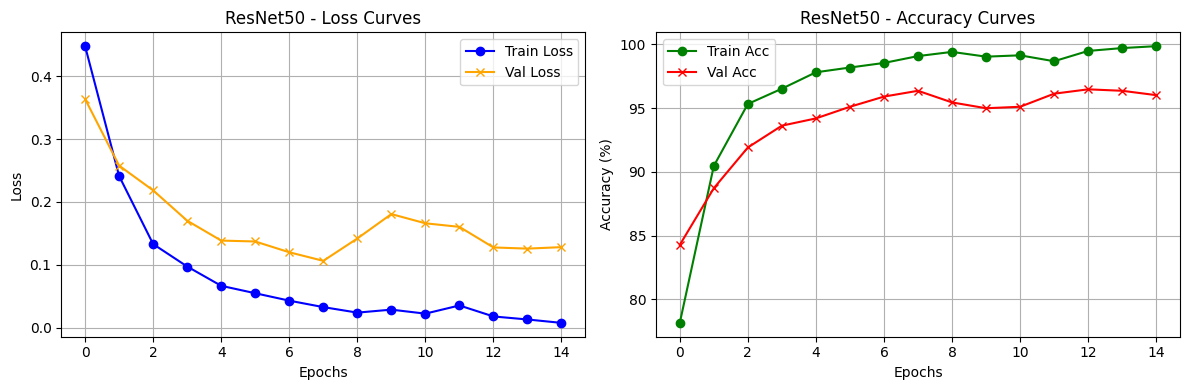

In [ ]:
import json
import matplotlib.pyplot as plt

with open('best_results.json', 'r') as f:
    data = json.load(f)

info = data["resnet50"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(info["train_losses"], label='Train Loss', color='blue', marker='o')
ax1.plot(info["val_losses"], label='Val Loss', color='orange', marker='x')
ax1.set_title('ResNet50 - Loss Curves')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(info["train_accs"], label='Train Acc', color='green', marker='o')
ax2.plot(info["val_accs"], label='Val Acc', color='red', marker='x')
ax2.set_title('ResNet50 - Accuracy Curves')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

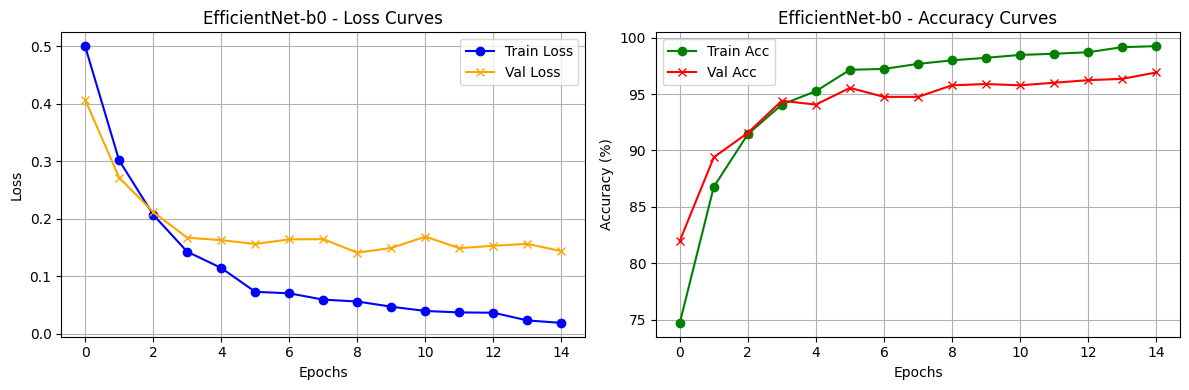

In [ ]:
import json
import matplotlib.pyplot as plt

with open('best_results.json', 'r') as f:
    data = json.load(f)

info = data["efficientnet_b0"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(info["train_losses"], label='Train Loss', color='blue', marker='o')
ax1.plot(info["val_losses"], label='Val Loss', color='orange', marker='x')
ax1.set_title('EfficientNet-b0 - Loss Curves')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(info["train_accs"], label='Train Acc', color='green', marker='o')
ax2.plot(info["val_accs"], label='Val Acc', color='red', marker='x')
ax2.set_title('EfficientNet-b0 - Accuracy Curves')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

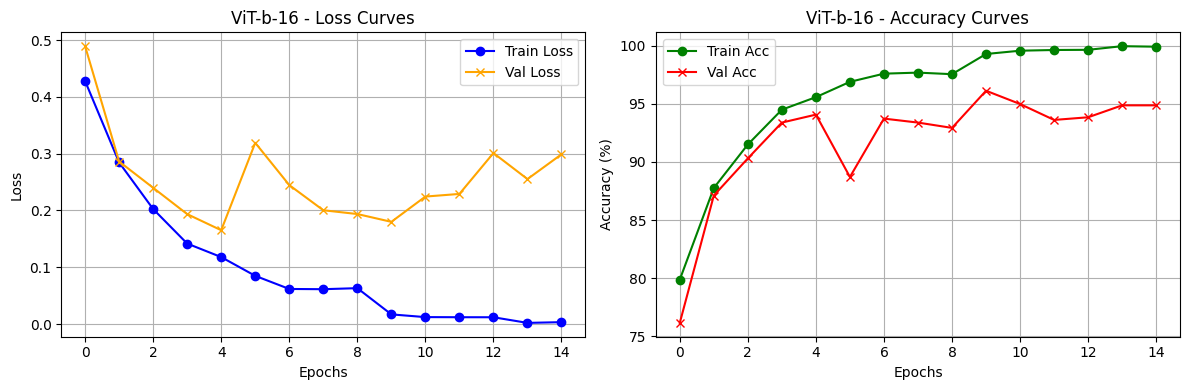

In [ ]:
import json
import matplotlib.pyplot as plt

with open('best_results.json', 'r') as f:
    data = json.load(f)

info = data["vit_b_16"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(info["train_losses"], label='Train Loss', color='blue', marker='o')
ax1.plot(info["val_losses"], label='Val Loss', color='orange', marker='x')
ax1.set_title('ViT-b-16 - Loss Curves')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(info["train_accs"], label='Train Acc', color='green', marker='o')
ax2.plot(info["val_accs"], label='Val Acc', color='red', marker='x')
ax2.set_title('ViT-b-16 - Accuracy Curves')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

     FINAL COMPARATIVE SUMMARY TABLE (3 MODELS)   


,Model Name,Train Loss,Val Loss,Test Loss,Train Acc (%),Val Acc (%),Test Acc (%),Precision,Recall,F1-Score (%)
0,RESNET50,0.0179,0.1277,0.1546,99.48,96.47,96.04,97.11,94.92,96.00
1,EFFICIENTNET_B0,0.0188,0.1436,0.1792,99.25,96.92,96.61,96.44,96.80,96.62
2,VIT_B_16,0.0169,0.1800,0.1933,99.28,96.12,95.66,95.67,95.67,95.67


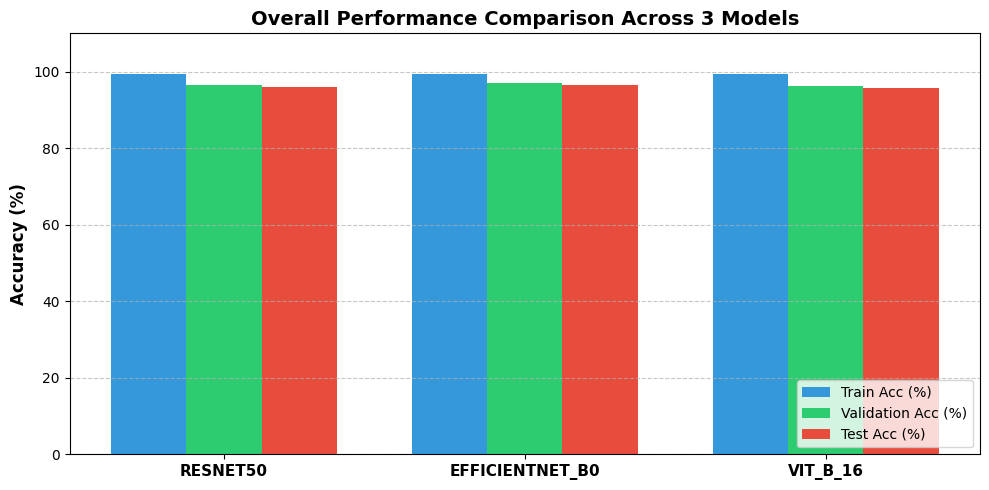

In [ ]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

with open('best_results (1).json', 'r') as f:
    data = json.load(f)

summary_rows = [info["metrics"] for info in data.values()]
df_summary = pd.DataFrame(summary_rows)

print("==================================================")
print("     FINAL COMPARATIVE SUMMARY TABLE (3 MODELS)   ")
print("==================================================")
display(df_summary)

# ওভারঅল বার চার্ট
models = df_summary["Model Name"]
train_accs = df_summary["Train Acc (%)"]
val_accs = df_summary["Val Acc (%)"]
test_accs = df_summary["Test Acc (%)"]

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width, train_accs, width, label='Train Acc (%)', color='#3498db')
ax.bar(x, val_accs, width, label='Validation Acc (%)', color='#2ecc71')
ax.bar(x + width, test_accs, width, label='Test Acc (%)', color='#e74c3c')

ax.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax.set_title('Overall Performance Comparison Across 3 Models', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=11, fontweight='bold')
ax.legend(loc='lower right')
ax.set_ylim(0, 110)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
import os
import json
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms, datasets
from torch.utils.data import DataLoader, Dataset
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device: {device}")

# ১. ডেটা ট্রান্সফর্মেশন ও অগমেন্টেশন (আগের মতোই)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ২. সেফ ইমেজ ফোল্ডার ক্লাস (করাপ্টেড ছবি ফিল্টার করার জন্য)
class SafeImageFolder(Dataset):
    def __init__(self, root_dir, transform=None):
        self.dataset = datasets.ImageFolder(root_dir)
        self.transform = transform
        valid_samples = []
        corrupted_count = 0
        print(f"Checking & cleaning corrupted images in {os.path.basename(root_dir)}...")
        for path, target in self.dataset.samples:
            try:
                with Image.open(path) as img:
                    img.verify()
                valid_samples.append((path, target))
            except Exception:
                corrupted_count += 1
                try:
                    os.remove(path)
                except:
                    pass
        self.samples = valid_samples
        print(f"-> Total Valid Images: {len(self.samples)} | Removed Corrupted Images: {corrupted_count}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, target = self.samples[idx]
        image = Image.open(path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(target, dtype=torch.long)

    @property
    def classes(self):
        return self.dataset.classes

# ৩. সাজানো ফোল্ডার থেকে ডেটাসেট লোড করা
DATA_DIR = "ASD Data/Perfect_Organized_Dataset"
TRAIN_DIR = os.path.join(DATA_DIR, "train1")
VAL_DIR = os.path.join(DATA_DIR, "valid1")
TEST_DIR = os.path.join(DATA_DIR, "test1")

print("--- Preparing Train Dataset ---")
train_dataset = SafeImageFolder(TRAIN_DIR, transform=train_transform)
print("\n--- Preparing Validation Dataset ---")
val_dataset = SafeImageFolder(VAL_DIR, transform=val_test_transform)
print("\n--- Preparing Test Dataset ---")
test_dataset = SafeImageFolder(TEST_DIR, transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f"\nFinal Ready -> Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")
print(f"Classes found: {train_dataset.classes}")

# ৪. নতুন ৩টি মডেল আর্কিটেকচার সেটআপ (ConvNeXt-Tiny, DenseNet121, Swin-Tiny)
def get_model(model_name):
    if model_name == "convnext_tiny":
        model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
        num_ftrs = model.classifier[2].in_features
        model.classifier[2] = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(num_ftrs, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )
    elif model_name == "densenet121":
        model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        num_ftrs = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(num_ftrs, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 2)
        )
    elif model_name == "swin_t":
        model = models.swin_t(weights=models.Swin_T_Weights.DEFAULT)
        num_ftrs = model.head.in_features
        model.head = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(num_ftrs, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )
    return model.to(device)

all_models_data = {}
models_to_run = ["convnext_tiny", "densenet121", "swin_t"]

# ৫. ট্রেনিং লুপ (১৫ ইপোক)
for model_name in models_to_run:
    print(f"\n================ Training Started: {model_name.upper()} ================")
    model = get_model(model_name)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=8e-5, weight_decay=1e-2)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

    train_losses, val_losses, train_accs, val_accs = [], [], [], []
    best_val_acc = 0.0
    best_test_metrics = {}
    true_labels, pred_labels = [], []

    for epoch in range(15):
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total_train += labels.size(0)
            correct_train += predicted.eq(labels).sum().item()

        t_loss = running_loss / total_train
        t_acc = (correct_train / total_train) * 100
        train_losses.append(t_loss)
        train_accs.append(t_acc)

        # Validation
        model.eval()
        running_val_loss, correct_val, total_val = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                running_val_loss += loss.item() * images.size(0)
                _, predicted = outputs.max(1)
                total_val += labels.size(0)
                correct_val += predicted.eq(labels).sum().item()

        v_loss = running_val_loss / total_val
        v_acc = (correct_val / total_val) * 100
        val_losses.append(v_loss)
        val_accs.append(v_acc)
        scheduler.step(v_loss)

        print(f"Epoch [{epoch+1}/15]  |  T.Loss: {t_loss:.4f}  |  T.Acc: {t_acc:.2f}%  |  V.Loss: {v_loss:.4f}  |  V.Acc: {v_acc:.2f}%")

        if v_acc > best_val_acc:
            best_val_acc = v_acc
            torch.save(model.state_dict(), f"best_{model_name}_asd.pth")

            # Test Evaluation on Best Epoch
            running_test_loss, correct_test, total_test = 0.0, 0, 0
            t_labels, p_labels = [], []
            with torch.no_grad():
                for images, labels in test_loader:
                    images, labels = images.to(device), labels.to(device)
                    outputs = model(images)
                    loss = criterion(outputs, labels)
                    running_test_loss += loss.item() * images.size(0)
                    _, predicted = outputs.max(1)
                    total_test += labels.size(0)
                    correct_test += predicted.eq(labels).sum().item()
                    t_labels.extend(labels.cpu().tolist())
                    p_labels.extend(predicted.cpu().tolist())

            test_loss = running_test_loss / total_test
            test_acc = (correct_test / total_test) * 100
            true_labels = t_labels
            pred_labels = p_labels

            best_test_metrics = {
                "Model Name": model_name.upper(),
                "Train Loss": round(t_loss, 4),
                "Val Loss": round(v_loss, 4),
                "Test Loss": round(test_loss, 4),
                "Train Acc (%)": round(t_acc, 2),
                "Val Acc (%)": round(v_acc, 2),
                "Test Acc (%)": round(test_acc, 2)
            }

    # Confusion Matrix & Metrics Calculation
    cm = [[0, 0], [0, 0]]
    for t, p in zip(true_labels, pred_labels):
        cm[t][p] += 1

    TP, FP, FN, TN = cm[1][1], cm[0][1], cm[1][0], cm[0][0]
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    best_test_metrics["Precision"] = round(precision * 100, 2)
    best_test_metrics["Recall"] = round(recall * 100, 2)
    best_test_metrics["F1-Score (%)"] = round(f1_score * 100, 2)

    all_models_data[model_name] = {
        "metrics": best_test_metrics,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs,
        "confusion_matrix": cm
    }

# Save results to a new json file
with open('asd_results_new.json', 'w') as f:
    json.dump(all_models_data, f, indent=4)

print("\nTraining Completed Successfully for ConvNeXt, DenseNet, and Swin-Transformer!")

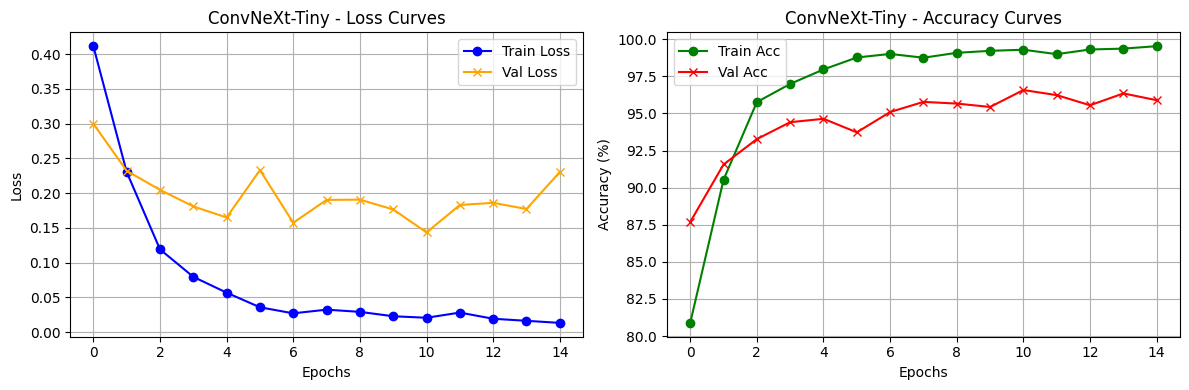

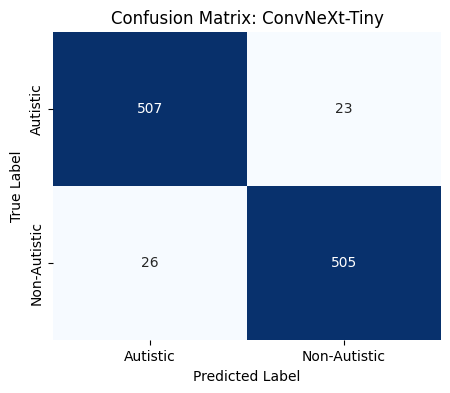

In [4]:
import json
import matplotlib.pyplot as plt
import seaborn as sns

with open('asd_results_new.json', 'r') as f:
    data = json.load(f)

info = data["convnext_tiny"]

# গ্রাফ (Loss & Accuracy)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(info["train_losses"], label='Train Loss', color='blue', marker='o')
ax1.plot(info["val_losses"], label='Val Loss', color='orange', marker='x')
ax1.set_title('ConvNeXt-Tiny - Loss Curves')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(info["train_accs"], label='Train Acc', color='green', marker='o')
ax2.plot(info["val_accs"], label='Val Acc', color='red', marker='x')
ax2.set_title('ConvNeXt-Tiny - Accuracy Curves')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)
plt.tight_layout()
plt.show()

# কনফিউশন ম্যাট্রিক্স
plt.figure(figsize=(5, 4))
sns.heatmap(info["confusion_matrix"], annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Autistic', 'Non-Autistic'], yticklabels=['Autistic', 'Non-Autistic'])
plt.title('Confusion Matrix: ConvNeXt-Tiny')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

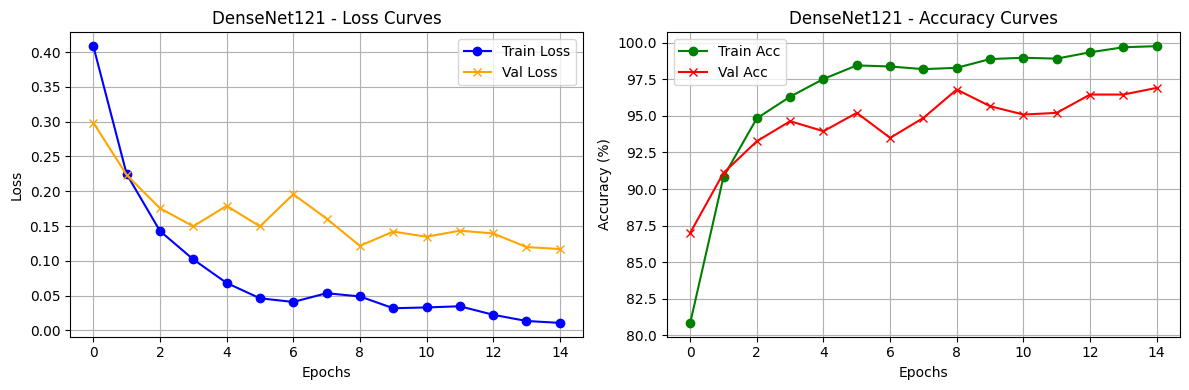

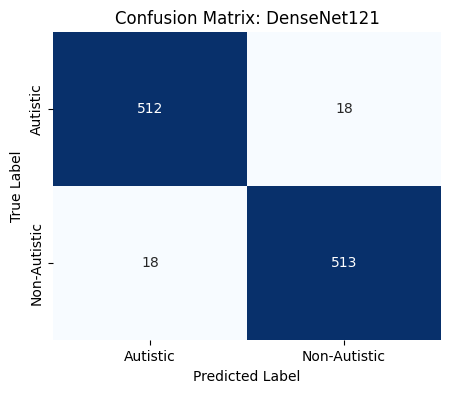

In [5]:
with open('asd_results_new.json', 'r') as f:
    data = json.load(f)

info = data["densenet121"]

# গ্রাফ (Loss & Accuracy)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(info["train_losses"], label='Train Loss', color='blue', marker='o')
ax1.plot(info["val_losses"], label='Val Loss', color='orange', marker='x')
ax1.set_title('DenseNet121 - Loss Curves')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(info["train_accs"], label='Train Acc', color='green', marker='o')
ax2.plot(info["val_accs"], label='Val Acc', color='red', marker='x')
ax2.set_title('DenseNet121 - Accuracy Curves')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)
plt.tight_layout()
plt.show()

# কনফিউশন ম্যাট্রিক্স
plt.figure(figsize=(5, 4))
sns.heatmap(info["confusion_matrix"], annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Autistic', 'Non-Autistic'], yticklabels=['Autistic', 'Non-Autistic'])
plt.title('Confusion Matrix: DenseNet121')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

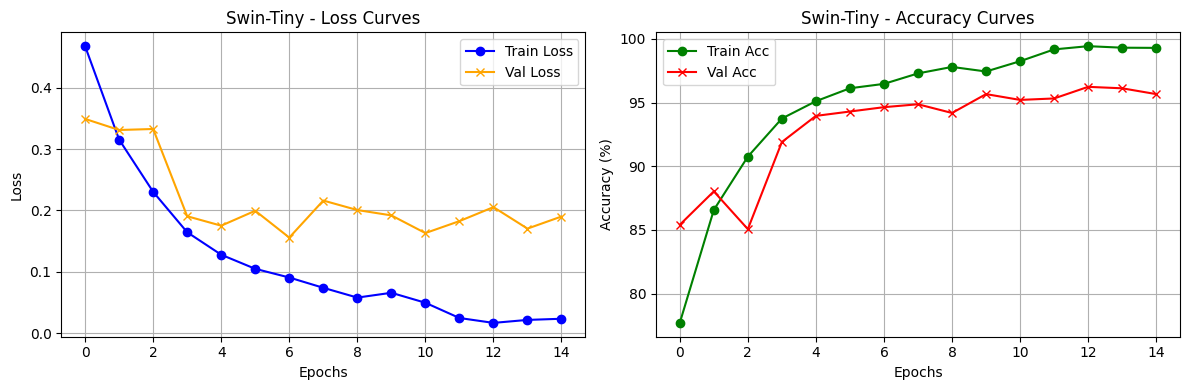

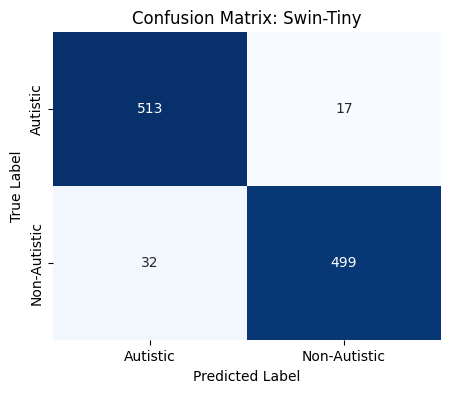

In [6]:
with open('asd_results_new.json', 'r') as f:
    data = json.load(f)

info = data["swin_t"]

# গ্রাফ (Loss & Accuracy)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(info["train_losses"], label='Train Loss', color='blue', marker='o')
ax1.plot(info["val_losses"], label='Val Loss', color='orange', marker='x')
ax1.set_title('Swin-Tiny - Loss Curves')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(info["train_accs"], label='Train Acc', color='green', marker='o')
ax2.plot(info["val_accs"], label='Val Acc', color='red', marker='x')
ax2.set_title('Swin-Tiny - Accuracy Curves')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)
plt.tight_layout()
plt.show()

# কনফিউশন ম্যাট্রিক্স
plt.figure(figsize=(5, 4))
sns.heatmap(info["confusion_matrix"], annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Autistic', 'Non-Autistic'], yticklabels=['Autistic', 'Non-Autistic'])
plt.title('Confusion Matrix: Swin-Tiny')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

     FINAL COMPARATIVE SUMMARY TABLE (3 MODELS)   


,Model Name,Train Loss,Val Loss,Test Loss,Train Acc (%),Val Acc (%),Test Acc (%),Precision,Recall,F1-Score (%)
0,CONVNEXT_TINY,0.0207,0.1435,0.1777,99.30,96.58,95.38,95.64,95.10,95.37
1,DENSENET121,0.0107,0.1169,0.1377,99.78,96.92,96.61,96.61,96.61,96.61
2,SWIN_T,0.0166,0.2053,0.2449,99.43,96.24,95.38,96.71,93.97,95.32


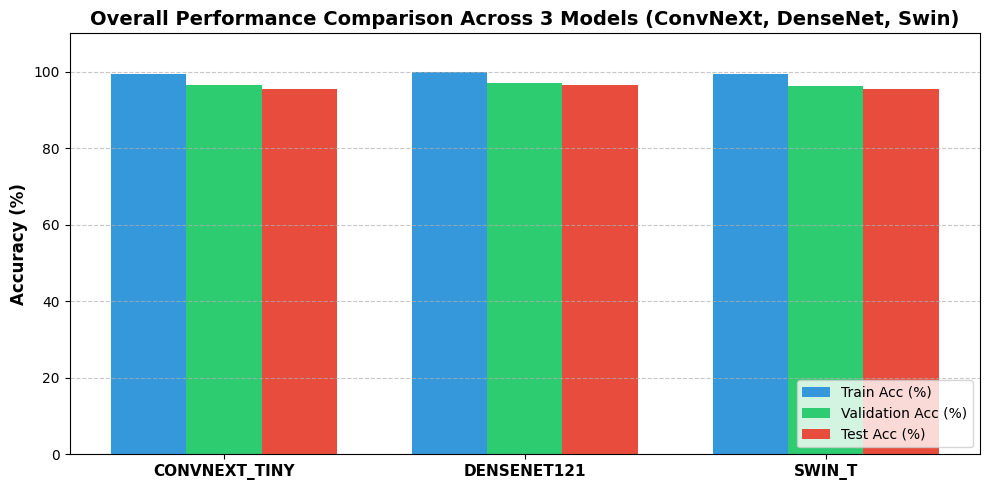

In [7]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


with open('asd_results_new.json', 'r') as f:
    data = json.load(f)

summary_rows = [info["metrics"] for info in data.values()]
df_summary = pd.DataFrame(summary_rows)

print("==================================================")
print("     FINAL COMPARATIVE SUMMARY TABLE (3 MODELS)   ")
print("==================================================")
display(df_summary)

# ওভারঅল বার চার্ট
models = df_summary["Model Name"]
train_accs = df_summary["Train Acc (%)"]
val_accs = df_summary["Val Acc (%)"]
test_accs = df_summary["Test Acc (%)"]

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width, train_accs, width, label='Train Acc (%)', color='#3498db')
ax.bar(x, val_accs, width, label='Validation Acc (%)', color='#2ecc71')
ax.bar(x + width, test_accs, width, label='Test Acc (%)', color='#e74c3c')

ax.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax.set_title('Overall Performance Comparison Across 3 Models (ConvNeXt, DenseNet, Swin)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=11, fontweight='bold')
ax.legend(loc='lower right')
ax.set_ylim(0, 110)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

     COMBINED COMPARATIVE SUMMARY TABLE (ALL MODELS)   


,Model Name,Train Loss,Val Loss,Test Loss,Train Acc (%),Val Acc (%),Test Acc (%),Precision,Recall,F1-Score (%)
0,RESNET50,0.0179,0.1277,0.1546,99.48,96.47,96.04,97.11,94.92,96.00
1,EFFICIENTNET_B0,0.0188,0.1436,0.1792,99.25,96.92,96.61,96.44,96.80,96.62
2,VIT_B_16,0.0169,0.1800,0.1933,99.28,96.12,95.66,95.67,95.67,95.67
3,CONVNEXT_TINY,0.0207,0.1435,0.1777,99.30,96.58,95.38,95.64,95.10,95.37
4,DENSENET121,0.0107,0.1169,0.1377,99.78,96.92,96.61,96.61,96.61,96.61
5,SWIN_T,0.0166,0.2053,0.2449,99.43,96.24,95.38,96.71,93.97,95.32


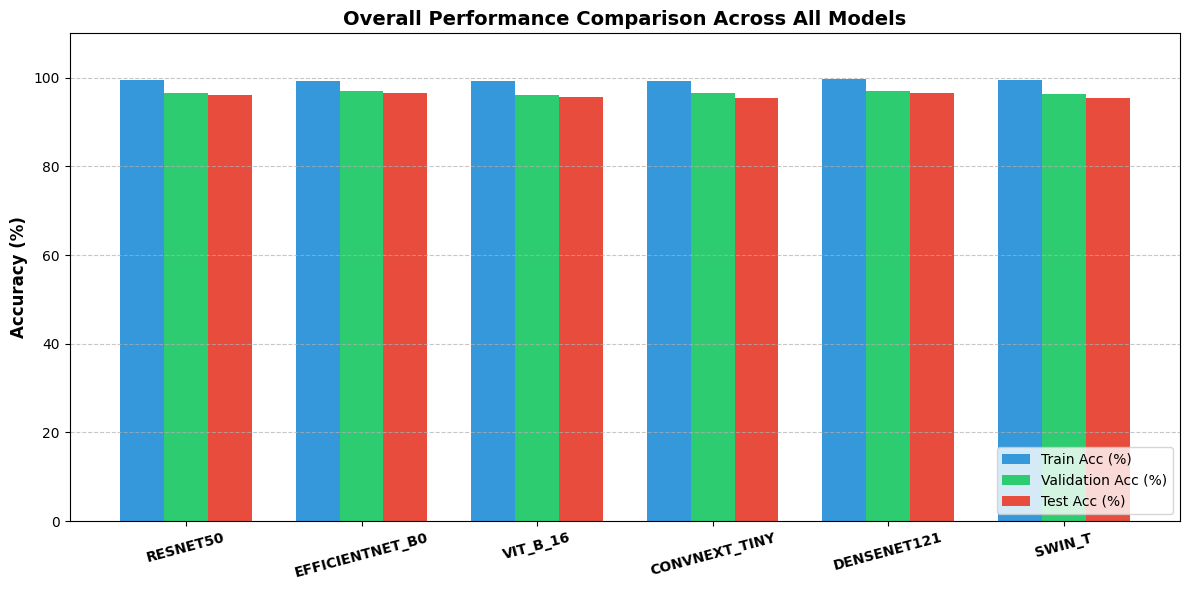

In [ ]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ১. দুটি JSON ফাইল থেকেই ডেটা রিড করা
json_files = ['best_results (1).json', 'asd_results_new.json']
combined_data = {}

for json_file in json_files:
    if os.path.exists(json_file):
        with open(json_file, 'r') as f:
            try:
                content = json.load(f)
                if isinstance(content, dict):
                    combined_data.update(content)
            except Exception as e:
                print(f"Could not read {json_file}: {e}")

# ২. সমস্ত মডেলের মেট্রিক্স ফিল্টার করে সামারি টেবিল তৈরি
summary_rows = []
for model_key, info in combined_data.items():
    metrics = info.get('metrics', info)
    summary_rows.append(metrics)

df_summary = pd.DataFrame(summary_rows)

# Duplicate Model বাদ দেওয়া (যদি দুটি ফাইলে একই মডেল থাকে)
if 'Model Name' in df_summary.columns:
    df_summary = df_summary.drop_duplicates(subset=['Model Name'])

print("==================================================")
print("     COMBINED COMPARATIVE SUMMARY TABLE (ALL MODELS)   ")
print("==================================================")
display(df_summary)

# ৩. ওভারঅল বার-চার্ট ভিজ্যুয়ালাইজেশন
models = df_summary["Model Name"]
train_accs = df_summary["Train Acc (%)"]
val_accs = df_summary["Val Acc (%)"]
test_accs = df_summary["Test Acc (%)"]

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width, train_accs, width, label='Train Acc (%)', color='#3498db')
ax.bar(x, val_accs, width, label='Validation Acc (%)', color='#2ecc71')
ax.bar(x + width, test_accs, width, label='Test Acc (%)', color='#e74c3c')

ax.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax.set_title('Overall Performance Comparison Across All Models', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=10, fontweight='bold', rotation=15)
ax.legend(loc='lower right')
ax.set_ylim(0, 110)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
!pip install mtcnn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 10.9 MB/s  0:00:00


Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


✅ Successfully Loaded Weights for: EFFICIENTNET_B0


Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.



================ GRAD-CAM + EIGEN-CAM RESULT ================
📁 Image Path: images (14).jfif
🤖 Model Prediction: AUTISTIC
✅ Successfully Saved Fixed Grid Image as: 'cam_visualization_grid.png'


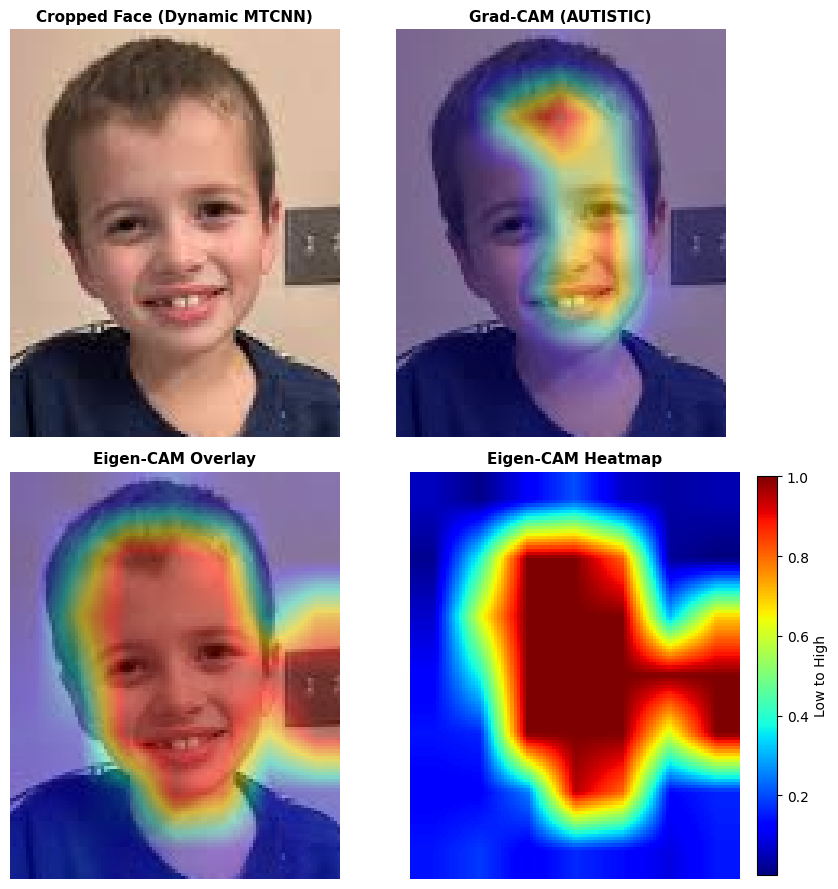

In [ ]:
import os
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from mtcnn import MTCNN

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =====================================================================
# ১. মডেল এবং ওয়েট ফাইল কনফিগারেশন
# =====================================================================
SELECTED_MODEL_NAME = "efficientnet_b0"
MODEL_WEIGHTS_PATH = "best_efficientnet_b0_asd (1).pth"

if SELECTED_MODEL_NAME == "resnet50":
    model = models.resnet50(weights=None)
    num_ftrs = model.fc.in_features
    model.fc = nn.Sequential(nn.Linear(num_ftrs, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.4), nn.Linear(512, 2))
    target_layer = model.layer4[2].conv3
elif SELECTED_MODEL_NAME == "efficientnet_b0":
    model = models.efficientnet_b0(weights=None)
    num_ftrs = model.classifier[1].in_features
    model.classifier[1] = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_ftrs, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 2))
    target_layer = model.features[-1]
elif SELECTED_MODEL_NAME == "vit_b_16":
    model = models.vit_b_16(weights=None)
    num_ftrs = model.heads.head.in_features
    model.heads.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_ftrs, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 2))
    target_layer = model.encoder.layers.encoder_layer_11.ln_1

model = model.to(device)

if os.path.exists(MODEL_WEIGHTS_PATH):
    model.load_state_dict(torch.load(MODEL_WEIGHTS_PATH, map_location=device))
    print(f"✅ Successfully Loaded Weights for: {SELECTED_MODEL_NAME.upper()}")
else:
    print(f"❌ Error: Weights file '{MODEL_WEIGHTS_PATH}' not found!")
model.eval()

# =====================================================================
# ২. Grad-CAM ক্লাস (ক্লাস-ডিপেন্ডেন্ট লোকলাইজেশন)
# =====================================================================
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.forward_handle = target_layer.register_forward_hook(self.save_activation)
        self.backward_handle = target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_out):
        self.gradients = grad_out[0].detach()

    def remove_hooks(self):
        self.forward_handle.remove()
        self.backward_handle.remove()

    def __call__(self, x, class_idx=None):
        self.model.eval()
        output = self.model(x)

        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        score = output[:, class_idx]
        self.model.zero_grad()
        score.backward(retain_graph=True)

        gradients = self.gradients[0]
        activations = self.activations[0]

        weights = gradients.mean(dim=(1, 2), keepdim=True)
        cam = (weights * activations).sum(dim=0)

        cam = F.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam.cpu().numpy(), class_idx

# =====================================================================
# ৩. Eigen-CAM ক্লাস (ক্লাস-ইন্ডিপেন্ডেন্ট প্রিন্সিপাল কম্পোনেন্ট ম্যাপ)
# =====================================================================
class EigenCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.hook_handle = target_layer.register_forward_hook(self.save_activation)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def remove_hook(self):
        self.hook_handle.remove()

    def __call__(self, x):
        self.model.eval()
        with torch.no_grad():
            _ = self.model(x)

        act = self.activations[0].cpu().numpy()
        c, h, w = act.shape
        flat_act = act.reshape(c, -1)
        flat_act = flat_act - np.mean(flat_act, axis=1, keepdims=True)

        U, S, Vt = np.linalg.svd(flat_act, full_matrices=False)
        eigen_cam = Vt[0, :].reshape(h, w)

        eigen_cam = np.maximum(eigen_cam, 0) # ReLU
        eigen_cam = eigen_cam - eigen_cam.min()
        eigen_cam = eigen_cam / (eigen_cam.max() + 1e-8)

        return eigen_cam

# =====================================================================
# ৪. ফুল ডাইনামিক ফেস ক্রপিং (MTCNN ডিটেক্টর ব্যবহার করে ১০০% রিলায়েবল)
# =====================================================================
detector = MTCNN()

def extract_face(image_path, padding=25):
    img_cv = cv2.imread(image_path)
    if img_cv is None:
        return None

    h_img, w_img, _ = img_cv.shape
    img_rgb = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)

    # ডাইনামিকভাবে মুখ ডিটেক্ট করা
    faces = detector.detect_faces(img_rgb)

    if len(faces) > 0:
        x, y, w, h = faces[0]['box']

        x1 = max(0, x - padding)
        y1 = max(0, y - padding)
        x2 = min(w_img, x + w + padding)
        y2 = min(h_img, y + h + padding)

        face_crop = img_cv[y1:y2, x1:x2]
        face_rgb = cv2.cvtColor(face_crop, cv2.COLOR_BGR2RGB)
        return Image.fromarray(face_rgb)
    else:
        print("⚠️ Warning: MTCNN could not detect face, using dynamic upper-center fallback.")
        crop_w = int(w_img * 0.45)
        crop_h = int(h_img * 0.45)
        x1 = max(0, (w_img - crop_w) // 2)
        y1 = max(0, int(h_img * 0.05))
        x2 = min(w_img, x1 + crop_w)
        y2 = min(h_img, y1 + crop_h)
        face_crop = img_cv[y1:y2, x1:x2]
        face_rgb = cv2.cvtColor(face_crop, cv2.COLOR_BGR2RGB)
        return Image.fromarray(face_rgb)

inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def to_rgb_heatmap(mask):
    hm = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)
    hm = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)
    return np.float32(hm) / 255

# =====================================================================
# ৫. মূল টেস্ট এবং ভিজ্যুয়ালাইজেশন ফাংশন (Grad-CAM + Eigen-CAM)
# =====================================================================
def test_gradcam_eigen_xai(image_path):
    if not os.path.exists(image_path):
        print(f"❌ Error: Image not found at '{image_path}'!")
        return

    cropped_face_image = extract_face(image_path)
    input_tensor = inference_transform(cropped_face_image).unsqueeze(0).to(device)

    # --- Grad-CAM জেনারেশন ---
    grad_cam = GradCAM(model, target_layer)
    cam_mask, pred_class = grad_cam(input_tensor)
    grad_cam.remove_hooks()
    cam_mask = cv2.resize(cam_mask, cropped_face_image.size)

    heatmap_g = to_rgb_heatmap(cam_mask)
    cropped_np = np.array(cropped_face_image) / 255.0
    overlay_g = heatmap_g * 0.4 + cropped_np * 0.6
    overlay_g = overlay_g / (overlay_g.max() + 1e-8)

    # --- Eigen-CAM জেনারেশন ---
    eigen_cam_method = EigenCAM(model, target_layer)
    eigen_mask = eigen_cam_method(input_tensor)
    eigen_cam_method.remove_hook()
    eigen_mask = cv2.resize(eigen_mask, cropped_face_image.size)

    # Eigen-CAM Sign Problem Fix
    h, w = eigen_mask.shape
    core_mean = eigen_mask[h//4:3*h//4, w//4:3*w//4].mean()
    if core_mean < eigen_mask.mean():
        eigen_mask = 1 - eigen_mask

    heatmap_e = to_rgb_heatmap(eigen_mask)
    overlay_e = heatmap_e * 0.4 + cropped_np * 0.6
    overlay_e = overlay_e / (overlay_e.max() + 1e-8)

    class_names = ['autistic', 'non_autistic']
    prediction = class_names[pred_class].upper()

    print(f"\n================ GRAD-CAM + EIGEN-CAM RESULT ================")
    print(f"📁 Image Path: {image_path}")
    print(f"🤖 Model Prediction: {prediction}")
    print(f"=============================================================")

    # প্লট করে একসাথে ৪টি গ্রিড দেখানো
    fig, axes = plt.subplots(2, 2, figsize=(9, 9))
    fig.patch.set_facecolor('#ffffff')

    axes[0, 0].imshow(cropped_face_image)
    axes[0, 0].set_title("Cropped Face (Dynamic MTCNN)", fontsize=11, fontweight='bold')
    axes[0, 0].axis('off')

    axes[0, 1].imshow(overlay_g)
    axes[0, 1].set_title(f"Grad-CAM ({prediction})", fontsize=11, fontweight='bold')
    axes[0, 1].axis('off')

    axes[1, 0].imshow(overlay_e)
    axes[1, 0].set_title("Eigen-CAM Overlay", fontsize=11, fontweight='bold')
    axes[1, 0].axis('off')

    im = axes[1, 1].imshow(eigen_mask, cmap='jet')
    axes[1, 1].set_title("Eigen-CAM Heatmap", fontsize=11, fontweight='bold')
    axes[1, 1].axis('off')

    fig.colorbar(im, ax=axes[1, 1], fraction=0.046, pad=0.04, label='Low to High')

    plt.tight_layout()
    output_image_path = 'cam_visualization_grid.png'
    plt.savefig(output_image_path, dpi=300, bbox_inches='tight')
    print(f"✅ Successfully Saved Fixed Grid Image as: '{output_image_path}'")
    plt.show()

# =====================================================================
# 🔍 আপনার টেস্ট করার ছবির পাথ দিয়ে রান করুন!
# =====================================================================
test_gradcam_eigen_xai("images (14).jfif")